# Exploración de datos — UCI Adult (ingreso > 50K)

**TC5061 · Operaciones de aprendizaje automático (MLOps)** · Semana 4, «Código de experimentación base con MLflow»
Alumno: Luis Pablo Guerrero Garza · A01794858

Este notebook es **sólo exploración**. Viene del notebook baseline de la semana 3, sin el modelado ni el registro en
MLflow, que ahora viven en el paquete `adult_income`:

| Qué | Dónde |
|---|---|
| Descarga, carga y limpieza | `adult_income/dataset.py` (`load_raw`, `clean`) |
| Preprocesamiento (pipeline) | `adult_income/features.py` (`build_preprocessor`) |
| Entrenamiento, evaluación y MLflow | `adult_income/modeling/train.py` |

Aquí se revisa la evidencia que justifica cada decisión de limpieza; la limpieza en sí no se reimplementa en celdas:
se llama a la misma función `clean()` que usa el script.

| Paso | Sección |
|---|---|
| 1 | Carga y descripción |
| 2 | Análisis exploratorio (EDA) |
| 3 | Evidencia para la limpieza y resultado de `clean()` |

## 0 · Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from adult_income.config import EXCLUDED, RAW_FILE
from adult_income.dataset import clean, load_raw

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 30)

for lib in (pd, np, matplotlib):
    print(f"{lib.__name__:<12} {lib.__version__}")

pandas       3.0.6
numpy        2.5.3
matplotlib   3.11.2


## 1 · Carga y descripción del dataset

`load_raw()` descarga `adult.data` de UCI a `data/raw/` la primera vez. El archivo no trae encabezado; los nombres de columna salen de `adult.names`, el archivo de descripción que
acompaña al dataset en UCI. Se carga **sin** interpretar todavía los valores faltantes: cómo vienen codificados es parte
de lo que se revisa en la limpieza.

In [2]:
df_raw = load_raw()
print("Origen:", RAW_FILE)
print(f"Registros: {df_raw.shape[0]:,} · Variables: {df_raw.shape[1]}")
df_raw.head()

Origen: D:\Dev\MNA\TC5061\tc5061-experimentacion-mlflow\data\raw\adult.data
Registros: 32,561 · Variables: 15


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# Tipos que infirió pandas, valores distintos y un ejemplo por variable.
pd.DataFrame({
    "tipo_pandas": df_raw.dtypes.astype(str),
    "valores_distintos": df_raw.nunique(),
    "ejemplo": df_raw.iloc[0],
})

,tipo_pandas,valores_distintos,ejemplo
age,int64,73,39
workclass,str,9,State-gov
fnlwgt,int64,21648,77516
education,str,16,Bachelors
education-num,int64,16,13
marital-status,str,7,Never-married
occupation,str,15,Adm-clerical
relationship,str,6,Not-in-family
race,str,5,White
sex,str,2,Male


### Diccionario de variables

| Variable | Tipo | Significado |
|---|---|---|
| `age` | Numérica entera | Edad en años |
| `workclass` | Categórica (8) | Tipo de empleador: privado, autoempleo, gobierno federal/estatal/local, sin pago, nunca ha trabajado |
| `fnlwgt` | Numérica entera | *Final weight*: peso muestral del censo; estima a cuántas personas de la población representa el registro |
| `education` | Categórica ordinal (16) | Último nivel educativo alcanzado (de *Preschool* a *Doctorate*) |
| `education-num` | Numérica entera | El mismo nivel educativo codificado como número (1–16) |
| `marital-status` | Categórica (7) | Estado civil |
| `occupation` | Categórica (14) | Ocupación |
| `relationship` | Categórica (6) | Rol dentro del hogar (*Husband*, *Wife*, *Own-child*, …) |
| `race` | Categórica (5) | Raza declarada |
| `sex` | Categórica (2) | Sexo |
| `capital-gain` | Numérica entera | Ganancias de capital del año (USD) |
| `capital-loss` | Numérica entera | Pérdidas de capital del año (USD) |
| `hours-per-week` | Numérica entera | Horas trabajadas por semana |
| `native-country` | Categórica (41) | País de origen |
| `income` | **Target** binario | `<=50K` o `>50K` |

Los dominios de las categóricas y la definición de `fnlwgt` se tomaron de `adult.names`. Según ese mismo archivo, los
registros se extrajeron del censo de 1994 con filtros: edad mayor de 16, ingreso bruto mayor de 100, `fnlwgt` mayor de 1 y
horas por semana mayores que 0. El modelo sólo describe a esa población.

## 2 · Análisis exploratorio (EDA)

Para el EDA se usa una copia con el target ya convertido a 0/1 (`>50K` = 1). Las decisiones de limpieza se toman y
documentan en el paso 3; aquí sólo se observa.

        registros  proporción
income                       
<=50K       24720      0.7592
>50K         7841      0.2408


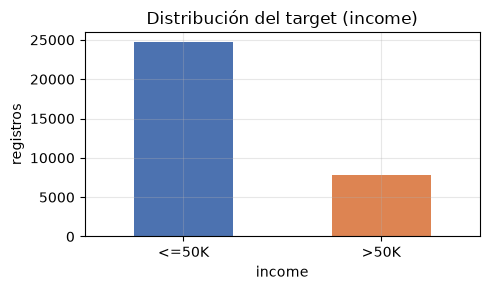

In [4]:
eda = df_raw.copy()
eda["y"] = (eda["income"] == ">50K").astype(int)

NUMERICAS = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
CATEGORICAS = ["workclass", "education", "marital-status", "occupation", "relationship", "race", "sex",
               "native-country"]

# Distribución del target: define qué métrica tiene sentido y cuál es el piso de un modelo trivial.
conteo = eda["income"].value_counts()
print(pd.DataFrame({"registros": conteo, "proporción": (conteo / len(eda)).round(4)}))

fig, ax = plt.subplots(figsize=(5, 3))
conteo.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], rot=0)
ax.set_title("Distribución del target (income)")
ax.set_ylabel("registros")
plt.tight_layout()
plt.show()

**Lectura.** El target está desbalanceado: 75.9 % `<=50K` y 24.1 % `>50K` (24,720 contra 7,841). La proporción es
coherente con la que reporta `adult.names` para el dataset completo (23.93 % de `>50K`). Tres consecuencias para el resto
del flujo:

- Un modelo que siempre diga `<=50K` ya tiene 75.9 % de exactitud; ése es el piso que hay que superar.
- La exactitud sola no sirve como métrica; hace falta una que mire la clase minoritaria (F1, recall, ROC-AUC).
- El split tiene que ser estratificado para que prueba conserve la misma proporción.

In [5]:
# Estadísticas descriptivas de las numéricas, con asimetría y porcentaje de ceros.
desc = eda[NUMERICAS].describe().T
desc["asimetría"] = eda[NUMERICAS].skew()
desc["% ceros"] = (eda[NUMERICAS] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría,% ceros
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0,0.56,0.00
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0,1.45,0.00
education-num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.31,0.00
capital-gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0,11.95,91.67
capital-loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0,4.59,95.33
hours-per-week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0,0.23,0.00


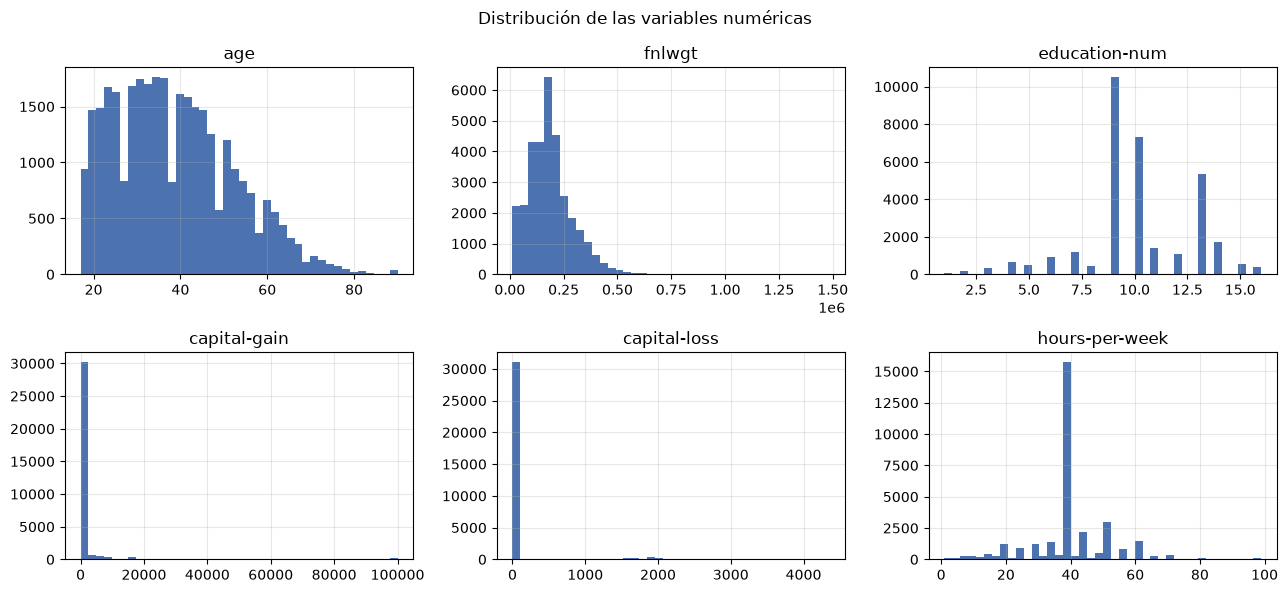

In [6]:
# Histogramas de las numéricas: forma de la distribución, colas y valores tope.
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), NUMERICAS):
    ax.hist(eda[col], bins=40, color="#4C72B0")
    ax.set_title(col)
fig.suptitle("Distribución de las variables numéricas")
plt.tight_layout()
plt.show()

**Lectura.**

- `age`: sesgo a la derecha (asimetría 0.56), mediana de 37 y la mitad central entre 28 y 48. El máximo de 90 se repite
  en varios registros, lo que sugiere un valor tope del censo (se revisa en 3.4).
- `fnlwgt`: cola larga a la derecha (hasta 1.48 millones). Es un peso muestral, no una característica de la persona.
- `education-num`: discreta (1–16), con picos en 9 (*HS-grad*), 10 (*Some-college*) y 13 (*Bachelors*).
- `capital-gain` y `capital-loss`: casi todo es cero (91.7 % y 95.3 %) y las colas son extremas (asimetría de 11.95 en
  `capital-gain`, con un máximo aislado en 99,999). En escala lineal estas variables dominarían a las demás; piden una
  transformación logarítmica.
- `hours-per-week`: muy concentrada en 40 (jornada completa) con colas a ambos lados, de 1 a 99.

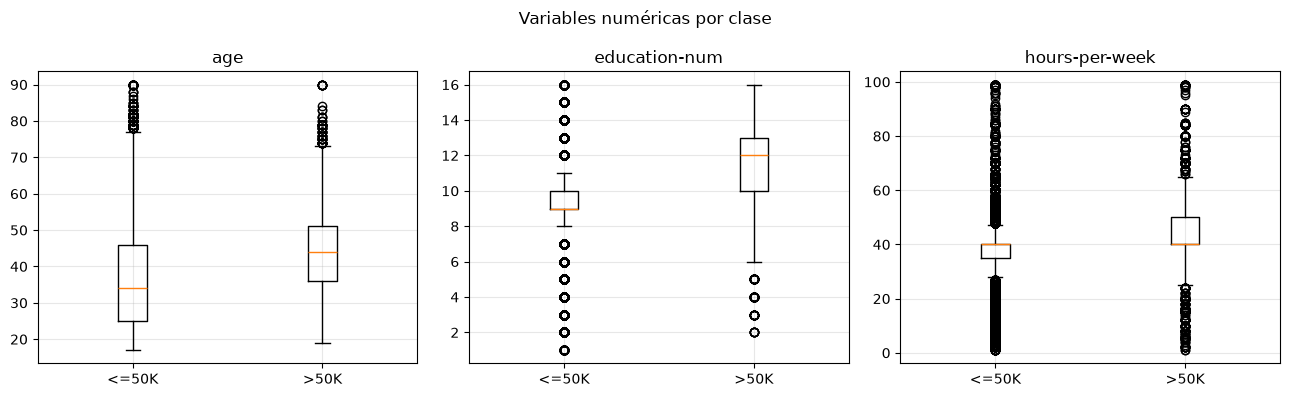

,age,education-num,hours-per-week
income,,,
<=50K,34.0,9.0,40.0
>50K,44.0,12.0,40.0


In [7]:
# Relación numérica–target: misma variable separada por clase.
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["age", "education-num", "hours-per-week"]):
    datos = [eda.loc[eda["y"] == k, col] for k in (0, 1)]
    ax.boxplot(datos, tick_labels=["<=50K", ">50K"])
    ax.set_title(col)
fig.suptitle("Variables numéricas por clase")
plt.tight_layout()
plt.show()

# Mediana por clase como apoyo numérico de la gráfica.
eda.groupby("income")[["age", "education-num", "hours-per-week"]].median()

**Lectura.** Quienes ganan `>50K` son mayores (mediana de 44 contra 34 años) y tienen más educación (12 contra 9, es
decir, grado asociado contra preparatoria). En horas la mediana es 40 en ambas clases, pero el resto de la distribución
cambia: en `>50K` el cuartil 1 es 40 y el 3 es 50, mientras que en `<=50K` van de 35 a 40. Las tres variables aportan señal,
y la edad y la educación son las que más separan.

In [8]:
# Resumen de las categóricas: cardinalidad, categoría más frecuente y su peso.
pd.DataFrame({
    "categorías": eda[CATEGORICAS].nunique(),
    "más frecuente": eda[CATEGORICAS].mode().iloc[0],
    "% más frecuente": [(eda[c].value_counts(normalize=True).iloc[0] * 100).round(1) for c in CATEGORICAS],
})

,categorías,más frecuente,% más frecuente
workclass,9,Private,69.7
education,16,HS-grad,32.3
marital-status,7,Married-civ-spouse,46.0
occupation,15,Prof-specialty,12.7
relationship,6,Husband,40.5
race,5,White,85.4
sex,2,Male,66.9
native-country,42,United-States,89.6


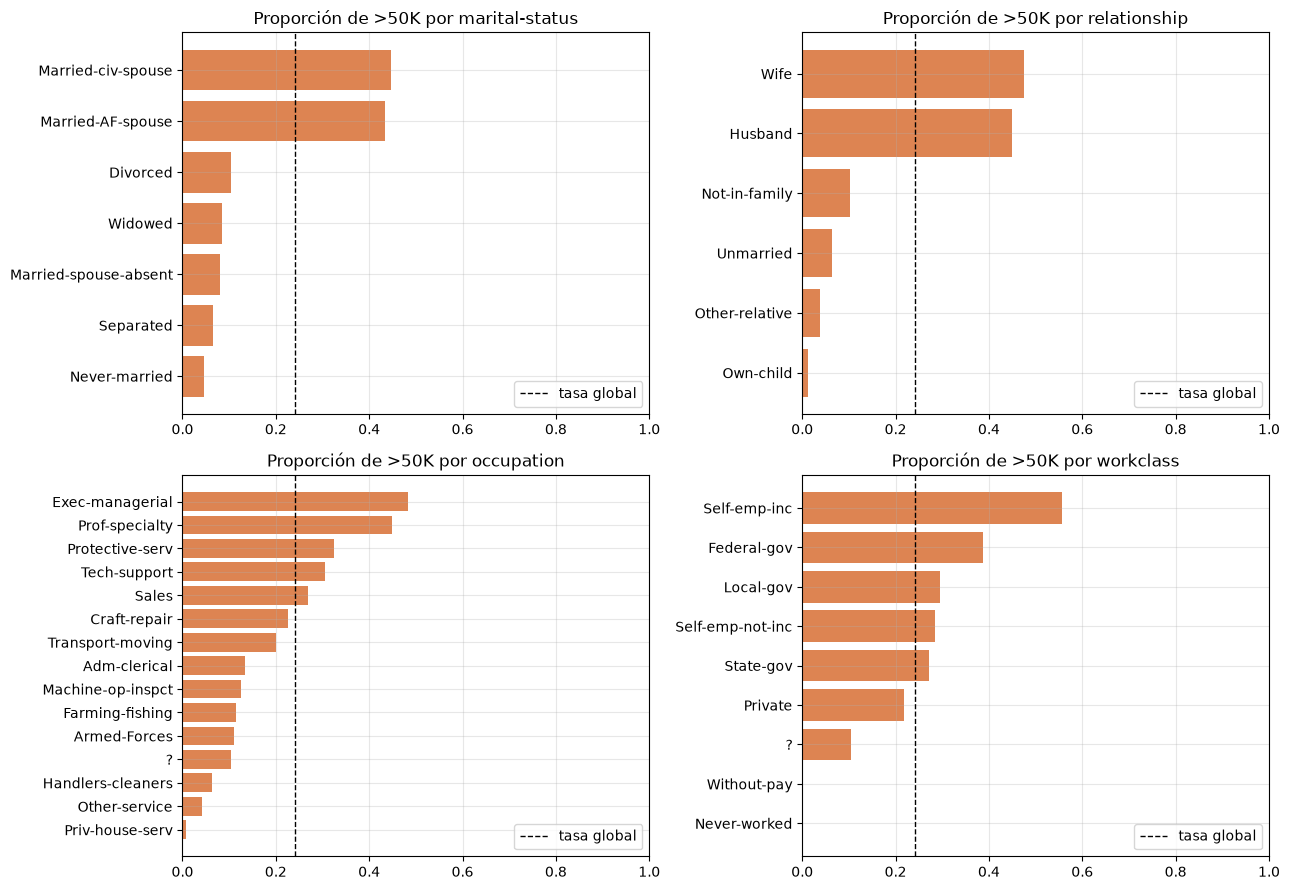

In [9]:
# Tasa de >50K por categoría: qué categóricas separan mejor las clases.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["marital-status", "relationship", "occupation", "workclass"]):
    tasa = eda.groupby(col)["y"].mean().sort_values()
    ax.barh(tasa.index, tasa.values, color="#DD8452")
    ax.axvline(eda["y"].mean(), color="black", ls="--", lw=1, label="tasa global")
    ax.set_title(f"Proporción de >50K por {col}")
    ax.set_xlim(0, 1)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lectura.** Estas cuatro categóricas separan mucho más que cualquier numérica:

- **Estado civil y rol en el hogar:** `Married-civ-spouse` tiene 44.7 % de `>50K` contra 4.6 % de `Never-married`, y
  `Husband`/`Wife` rondan 45–48 % contra 1.3 % de `Own-child`. Las dos variables están muy relacionadas (`Husband` y
  `Wife` sólo aparecen entre casados); para un baseline se conservan ambas, pero son candidatas a simplificarse.
- **Ocupación:** va de 0.7 % (`Priv-house-serv`) a 48.4 % (`Exec-managerial`) y 44.9 % (`Prof-specialty`).
- **Tipo de empleador:** `Self-emp-inc` tiene 55.7 %; el sector privado, que concentra 69.7 % de los registros, está en
  21.9 %.
- **El valor `?`** aparece como una categoría más en `workclass` y `occupation`, con una tasa de 10.4 %, muy por debajo
  de la global. El faltante no es aleatorio (se trata en 3.2).
- **Categorías con muy pocos registros** (`Never-worked` 7, `Armed-Forces` 9, `Without-pay` 14, `Married-AF-spouse` 23):
  sus tasas no son confiables.

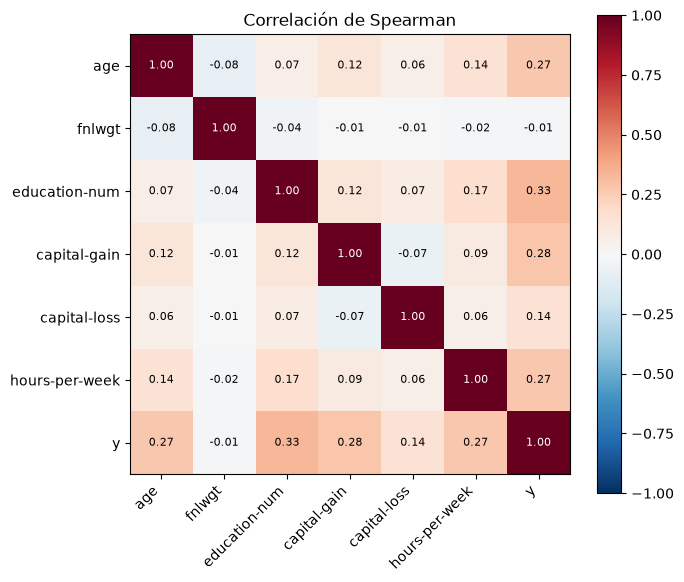

In [10]:
# Correlación de Spearman (por rangos: no asume linealidad y tolera las colas largas) entre numéricas y target.
corr = eda[NUMERICAS + ["y"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im)
ax.set_title("Correlación de Spearman")
ax.grid(False)
plt.tight_layout()
plt.show()

**Lectura.** Con el target, la correlación más alta es la de `education-num` (0.33); siguen `capital-gain` (0.28),
`age` y `hours-per-week` (0.27 cada una) y `capital-loss` (0.14). `fnlwgt` tiene −0.01, lo que confirma que el peso
muestral no informa sobre el ingreso. Entre predictores la correlación más alta es de apenas 0.17 (`education-num` con
`hours-per-week`), así que no hay multicolinealidad entre las numéricas.

In [11]:
# ¿education y education-num dicen lo mismo? Si cada nivel tiene un solo número, una de las dos sobra.
mapa = eda.groupby("education")["education-num"].agg(["nunique", "min"]).sort_values("min")
print("Números distintos por nivel educativo (máximo):", mapa["nunique"].max())
mapa.rename(columns={"nunique": "valores distintos", "min": "education-num"})

Números distintos por nivel educativo (máximo): 1


,valores distintos,education-num
education,,
Preschool,1,1
1st-4th,1,2
5th-6th,1,3
7th-8th,1,4
9th,1,5
10th,1,6
11th,1,7
12th,1,8
HS-grad,1,9


**Lectura.** Cada nivel de `education` corresponde a un único valor de `education-num` y el orden coincide, de
*Preschool* = 1 a *Doctorate* = 16. Son la misma información en dos formatos. Se conserva `education-num` porque ya es
ordinal y numérica y no necesita one-hot; `education` se excluye en 3.5.

## 3 · Limpieza de datos

Cada problema se revisa con evidencia y la decisión se justifica. La regla que guía todo: **lo que se aprende de los
datos (medias, categorías, escalas) se ajusta sólo con el conjunto de entrenamiento**, dentro del pipeline de `adult_income/features.py`.
Las transformaciones que no aprenden nada de los datos están en `clean()` (`adult_income/dataset.py`); aquí sólo se revisa la evidencia y al final se aplica esa función.

### 3.1 · Tipos y formato

In [12]:
# Espacios residuales: skipinitialspace quitó el de después de la coma; se verifica que no quede ninguno.
obj = df_raw.select_dtypes(exclude="number").columns  # columnas de texto
con_espacios = {c: int(df_raw[c].str.strip().ne(df_raw[c]).sum()) for c in obj}
print("Valores con espacios al inicio o final:", con_espacios)

# Etiquetas del target tal como vienen (adult.test las trae con punto final; adult.data no).
print("Etiquetas del target:", sorted(df_raw["income"].unique()))
print(df_raw.dtypes.value_counts())

Valores con espacios al inicio o final: {'workclass': 0, 'education': 0, 'marital-status': 0, 'occupation': 0, 'relationship': 0, 'race': 0, 'sex': 0, 'native-country': 0, 'income': 0}
Etiquetas del target: ['<=50K', '>50K']
str      9
int64    6
Name: count, dtype: int64


**Lectura.** No quedaron espacios residuales y el target sólo tiene las dos etiquetas esperadas (sin la variante con
punto final). Los tipos que infirió pandas son correctos: las 6 numéricas son enteras y las categóricas, texto. El único
cambio de tipo es el target, de texto a entero 0/1 (lo hace `clean()`). Las categóricas se codifican con one-hot dentro del pipeline.

### 3.2 · Valores faltantes

In [13]:
# pandas no reporta nulos porque los faltantes vienen codificados como el texto "?".
print("Nulos que ve pandas:", int(df_raw.isna().sum().sum()))

faltantes = (df_raw[obj] == "?").sum()
faltantes = faltantes[faltantes > 0]
pd.DataFrame({"registros con '?'": faltantes, "%": (faltantes / len(df_raw) * 100).round(2)})

Nulos que ve pandas: 0


,registros con '?',%
workclass,1836,5.64
occupation,1843,5.66
native-country,583,1.79


In [14]:
# ¿Los faltantes se concentran en los mismos registros?
f_work, f_occ, f_pais = (df_raw[c] == "?" for c in ["workclass", "occupation", "native-country"])
print("workclass='?' y occupation='?' a la vez:", int((f_work & f_occ).sum()))
print("occupation='?' con workclass conocido:   ", int((f_occ & ~f_work).sum()),
      "->", df_raw.loc[f_occ & ~f_work, "workclass"].value_counts().to_dict())
print("Registros con al menos un '?':           ", int((f_work | f_occ | f_pais).sum()))

# ¿Ser faltante se asocia con el target? Si sí, borrar esos registros sesga la muestra.
print("\nTasa de >50K")
print(f"  global:              {eda['y'].mean():.3f}")
print(f"  con occupation='?':  {eda.loc[f_occ, 'y'].mean():.3f}")
print(f"  con native-country='?': {eda.loc[f_pais, 'y'].mean():.3f}")

workclass='?' y occupation='?' a la vez: 1836
occupation='?' con workclass conocido:    7 -> {'Never-worked': 7}
Registros con al menos un '?':            2399

Tasa de >50K
  global:              0.241
  con occupation='?':  0.104
  con native-country='?': 0.250


**Lectura.**

- **Codificación oculta:** pandas reporta 0 nulos porque los faltantes vienen como el texto `"?"`. Sin esta revisión
  pasarían como una categoría válida.
- **Patrón:** los 1,836 registros con `workclass` faltante tienen también `occupation` faltante. Los 7 registros
  restantes de `occupation` faltante son de `workclass = Never-worked`: más que «desconocido», ahí la ocupación «no
  aplica».
- **Volumen:** en total, 2,399 registros (7.4 %) tienen al menos un `?`.
- **No es aleatorio:** con `occupation` faltante, la tasa de `>50K` es 10.4 % contra 24.1 % global.

**Decisión:** no borrar esos registros. Perder 7.4 % de los datos, concentrado en un grupo con ingreso más bajo, sesgaría
la muestra hacia ingresos altos. Se convierte `"?"` en `NaN` y el pipeline lo imputa con una categoría propia,
`"Desconocido"`, para que el modelo pueda usar el hecho de que falta. Imputar con la moda (`Private`, `Prof-specialty`)
inventaría información y borraría esa señal. Como la imputación es una constante, no aprende nada de los datos y no
introduce fuga.

### 3.3 · Duplicados

In [15]:
dups = df_raw.duplicated()
print(f"Registros duplicados exactos (las 15 columnas): {dups.sum()}")
# Se muestran todas las copias de algunos de ellos para inspeccionarlos.
df_raw[df_raw.duplicated(keep=False)].sort_values(list(df_raw.columns)).head(6)

Registros duplicados exactos (las 15 columnas): 24


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
17673,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
18698,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
6990,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
21318,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
15189,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
21490,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K


**Lectura.** Hay 24 registros idénticos en las 15 columnas, incluido `fnlwgt`, que tiene más de 21 mil valores
distintos. Que coincida también el peso muestral hace muy improbable que sean dos personas distintas con el mismo perfil.
`adult.names` reporta además 6 instancias «duplicadas o en conflicto» en el dataset completo.

**Decisión:** eliminar las copias y conservar la primera aparición. Son 0.07 % de los datos, así que el efecto en la
distribución es nulo, pero si una copia queda en entrenamiento y otra en prueba, el modelo se evalúa con un registro
que ya vio. Por eso se quitan **antes** del split.

### 3.4 · Outliers

Se cuentan con la regla de Tukey (fuera de 1.5 × IQR) y se revisan los valores extremos para distinguir errores de
valores reales.

In [16]:
# Los outliers se cuentan sin las copias, igual que en el dataset limpio.
sin_dup = eda.drop_duplicates()


def resumen_outliers(s: pd.Series) -> dict:
    """Cuenta valores fuera de [Q1 - 1.5·IQR, Q3 + 1.5·IQR] y reporta el máximo."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    return {"fuera de 1.5·IQR": int(fuera.sum()), "%": round(fuera.mean() * 100, 2),
            "mínimo": s.min(), "máximo": s.max()}

pd.DataFrame({c: resumen_outliers(sin_dup[c]) for c in NUMERICAS}).T

,fuera de 1.5·IQR,%,mínimo,máximo
age,142.0,0.44,17.0,90.0
fnlwgt,993.0,3.05,12285.0,1484705.0
education-num,1193.0,3.67,1.0,16.0
capital-gain,2712.0,8.34,0.0,99999.0
capital-loss,1519.0,4.67,0.0,4356.0
hours-per-week,9002.0,27.67,1.0,99.0


In [17]:
# Valores tope: ¿cuántos registros tienen exactamente el máximo?
for col in ["age", "capital-gain", "hours-per-week"]:
    maximo = sin_dup[col].max()
    print(f"{col:<15} máximo={maximo:>6}  registros con ese valor={int((sin_dup[col] == maximo).sum())}")

# capital-gain: cuántos valores distintos de cero hay y cuál es el siguiente valor por debajo del tope.
cg = sin_dup.loc[sin_dup["capital-gain"] > 0, "capital-gain"]
print(f"\ncapital-gain > 0: {len(cg)} registros; segundo valor más alto: {cg[cg < cg.max()].max()}")
print("Tasa de >50K con capital-gain = 99999:", sin_dup.loc[sin_dup["capital-gain"] == 99999, "y"].mean().round(3))

age             máximo=    90  registros con ese valor=42
capital-gain    máximo= 99999  registros con ese valor=159
hours-per-week  máximo=    99  registros con ese valor=85

capital-gain > 0: 2712 registros; segundo valor más alto: 41310
Tasa de >50K con capital-gain = 99999: 1.0


**Lectura.** La regla de 1.5 × IQR no sirve igual para todas las variables:

- **`hours-per-week`:** marca 27.7 % de los registros como atípicos. No es que haya tantos errores: la mitad central
  está entre 40 y 45, un rango tan estrecho que cualquier jornada de 30 o 60 horas cae fuera.
- **`capital-gain` y `capital-loss`:** como más del 90 % son ceros, todo valor distinto de cero cuenta como atípico.

Los valores extremos están dentro de lo posible y se explican como **topes del censo**, no como errores de captura:

- `age = 90` aparece en 42 registros.
- `hours-per-week = 99` aparece en 85.
- `capital-gain = 99999` aparece en 159, y el siguiente valor más alto es 41,310. Es un código de «99,999 o más», no una
  cantidad exacta. Además, el 100 % de esos registros es `>50K`.

**Decisión:** conservar todos los valores. Borrarlos eliminaría precisamente a los casos de ingreso más alto, y
recortarlos (*winsorizar*) no cambia nada en los topes, que ya están recortados. Lo que sí se trata es su efecto en el
modelo: `capital-gain` y `capital-loss` pasan por `log1p` antes de estandarizarse, de modo que 99,999 queda en ~11.5 en
vez de dominar la escala. Las demás numéricas sólo se estandarizan.

### 3.5 · Variables que no entran al modelo

In [18]:
# fnlwgt: peso muestral (cuántas personas representa el registro), no un atributo de la persona.
# education: redundante con education-num (verificado en el EDA: correspondencia uno a uno).
# clean() aplica todo lo anterior: target 0/1, "?" -> NaN, sin duplicados y sin EXCLUDED.
df = clean(df_raw)
print("Variables excluidas:", EXCLUDED)
print(f"Dataset limpio: {df.shape[0]:,} registros × {df.shape[1]} columnas")
print("Faltantes que quedan para el imputador del pipeline:", df.isna().sum()[lambda s: s > 0].to_dict())
df.head()

Variables excluidas: ['fnlwgt', 'education']
Dataset limpio: 32,537 registros × 13 columnas
Faltantes que quedan para el imputador del pipeline: {'workclass': 1836, 'occupation': 1843, 'native-country': 582}


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


### 3.6 · Resumen de decisiones de limpieza

| # | Problema | Evidencia | Decisión | Por qué |
|---|---|---|---|---|
| 1 | Faltantes codificados como texto | 0 nulos para pandas; `"?"` en `workclass` (1,836), `occupation` (1,843) y `native-country` (583); 2,399 registros (7.4 %) | `"?"` → `NaN`; imputación con la constante `"Desconocido"` dentro del pipeline | El faltante es informativo (10.4 % de `>50K` contra 24.1 %); borrar sesga la muestra y la moda inventa información |
| 2 | Duplicados exactos | 24 registros idénticos, incluido `fnlwgt` | Eliminar antes del split | Evita que un mismo registro quede en entrenamiento y en prueba |
| 3 | Tipo del target | Texto `<=50K` / `>50K` | Entero 0/1 | Lo requieren las métricas de scikit-learn |
| 4 | Espacios en categóricas | Separador `", "`; 0 residuales tras `skipinitialspace` | Ninguna adicional | Verificado |
| 5 | Outliers y topes | `capital-gain` = 99,999 (159), `age` = 90 (42), `hours-per-week` = 99 (85); IQR marca 27.7 % de las horas | Conservar; `log1p` + escalado en `capital-gain` y `capital-loss` | Son valores reales o topes del censo, no errores, y concentran a los `>50K` |
| 6 | Variable sin significado para la persona | `fnlwgt` es peso muestral; correlación con el target −0.01 | Excluir | No describe a la persona y no aporta señal |
| 7 | Variable redundante | `education` ↔ `education-num` uno a uno | Excluir `education` | Misma información; la numérica ya es ordinal |
| 8 | Escala y codificación | Rangos de 1 a 99,999; 7 categóricas | `StandardScaler` y `OneHotEncoder(handle_unknown="ignore")` dentro del pipeline | Se ajustan sólo con entrenamiento (sin fuga); una categoría nueva en producción no rompe el modelo |

Resultado: **32,537 registros × 13 columnas** (12 predictores + target).

Las decisiones 1 a 7 están implementadas en `clean()` (`adult_income/dataset.py`); la 1 (imputación), la 5
(`log1p`) y la 8 (escala y one-hot), en `build_preprocessor()` (`adult_income/features.py`).

**Siguiente paso:** el entrenamiento ya no ocurre en un notebook. Se ejecuta desde la terminal, en la raíz del
repositorio:

```bash
python -m adult_income.modeling.train --help
```

## Declaración de uso de inteligencia artificial

Anthropic. (2026). Claude Code (modelo `claude-opus-5-5`) [Modelo de lenguaje grande], aplicación de escritorio,
utilizado para generación de código y depuración. https://claude.com/claude-code

La IA derivó este notebook del baseline de la semana 3: quitó el modelado y el registro en MLflow y reemplazó las
celdas que transformaban los datos por llamadas a `adult_income.dataset`. Los textos de lectura y la tabla de
decisiones vienen de ese notebook. Sus cifras se comprobaron contra las salidas de esta ejecución.